# Qian: selected-layer internal validation

Four separate 5-epoch experiments on one fixed 40/5-per-class split. Uses the existing linear-probe recipe, random classifier initialization, and no prototypes. QKV and attention scopes keep LayerNorms and MLPs frozen. Existing full-block configs retain their original behavior.

Run setup once, then choose one arm at a time. Actual duration is hardware-dependent; no training-minute cutoff is imposed so each arm can finish 5 epochs. This is development, not a CodaBench submission notebook. Commit/push these files to your branch before cloning in Colab.


In [1]:
REPO_URL = "https://github.com/keaidewoq/cs604-project.git"
BRANCH = "qq_selected_layer_validation"
REPO_DIR = "/content/repo"
DATA_DIR = "/content/data"
DRIVE_OUT = "/content/drive/MyDrive/CS604_RUNS"
ARMS = ["linear_probe", "qq_qkv_last1", "qq_qkv_last2", "qq_attention_last1"]
ARM = "linear_probe"  # Change this and rerun the experiment cell for each arm.
SPLIT_SEED = 42


## 1. Clone/update, install, mount Drive, download

In [2]:
import os, base64, subprocess
from getpass import getpass
from pathlib import Path

token = getpass("GitHub token (hidden; leave empty for public access): ")
env = os.environ.copy()
if token:
    auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
    env.update(GIT_CONFIG_COUNT="1", GIT_CONFIG_KEY_0="http.https://github.com/.extraheader",
               GIT_CONFIG_VALUE_0=f"Authorization: Basic {auth}")
try:
    if (Path(REPO_DIR) / ".git").exists():
        subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin", BRANCH], env=env, check=True)
        subprocess.run(["git", "-C", REPO_DIR, "checkout", BRANCH], check=True)
        subprocess.run(["git", "-C", REPO_DIR, "merge", "--ff-only", f"origin/{BRANCH}"], check=True)
    else:
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, REPO_DIR], env=env, check=True)
finally:
    del token, env
    if "auth" in globals(): del auth
os.chdir(REPO_DIR)


GitHub token (hidden; leave empty for public access): ··········


In [3]:
%pip install -r requirements.txt


In [4]:
from google.colab import drive
drive.mount("/content/drive")
assert Path(DRIVE_OUT).is_dir(), "Add CS604_RUNS or its shortcut to My Drive first."
subprocess.run(["python", "scripts/download_data.py", "--dest", DATA_DIR], check=True)


Mounted at /content/drive


CompletedProcess(args=['python', 'scripts/download_data.py', '--dest', '/content/data'], returncode=0)

## 2. Create and preserve the internal split
Uses the existing split helper on all 10,000 classes. This seeded split may differ from Ana’s pandas split. A source-manifest hash prevents reusing a split made from different training labels. Official validation images are not the internal holdout.

In [5]:
import hashlib, json, shutil
from collections import Counter
from src.pilot_sweep import build_pilot_root, read_label_file

source_hash = hashlib.sha256((Path(DATA_DIR) / "train.txt").read_bytes()).hexdigest()
SPLIT_ROOT, split_info = build_pilot_root(
    DATA_DIR, f"/content/qq_validation_{source_hash[:16]}", 10000, 5, SPLIT_SEED,
)
fit = read_label_file(SPLIT_ROOT / "train.txt")
holdout = read_label_file(SPLIT_ROOT / "val.txt")
assert len(fit) == 400000 and len(holdout) == 50000, split_info
assert len(Counter(y for _, y in fit)) == 10000
assert set(Counter(y for _, y in fit).values()) == {40}
assert set(Counter(y for _, y in holdout).values()) == {5}
assert len({p for p, _ in fit}) == len(fit)
assert len({p for p, _ in holdout}) == len(holdout)
assert not {p for p, _ in fit} & {p for p, _ in holdout}
SPLIT_ID = hashlib.sha256((SPLIT_ROOT / "train.txt").read_bytes()
                          + b"\0" + (SPLIT_ROOT / "val.txt").read_bytes()).hexdigest()
EXPERIMENT_ROOT = Path(DRIVE_OUT) / f"qq_selected_layer_{SPLIT_ID[:16]}"
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
for name in ("train.txt", "val.txt"):
    shutil.copy2(SPLIT_ROOT / name, EXPERIMENT_ROOT / name)
(EXPERIMENT_ROOT / "split.json").write_text(json.dumps({
    **split_info, "seed": SPLIT_SEED, "source_sha256": source_hash, "split_sha256": SPLIT_ID,
}, indent=2))
print(split_info, "Saved manifests:", EXPERIMENT_ROOT)


[pilot] built /content/qq_validation_d7c7ebd0a10e6e7a/c10000_h5_s42: {'classes': 10000, 'fit_images': 400000, 'holdout_images': 50000}
{'classes': 10000, 'fit_images': 400000, 'holdout_images': 50000} Saved manifests: /content/drive/MyDrive/CS604_RUNS/qq_selected_layer_4bae5d64c9c7ecfb


## 3. Select and train one arm
Change `ARM` here for each experiment. Each run logs exact trainable parameter names/counts before training and rejects a backbone fraction ≥5%. The shared trainer evaluates each epoch and saves best.pt and last.pt. A new run folder is retained for every attempt.

In [7]:
ARM = "qq_attention_last1"  # linear_probe | qq_qkv_last1 | qq_qkv_last2 | qq_attention_last1
import gc
import torch
from src.model import build_model
from src.train import train
from src.utils import load_config, apply_overrides

assert ARM in ARMS
assert torch.cuda.is_available(), "Select a GPU runtime before training."
cfg = load_config(f"configs/{ARM}.yaml")
apply_overrides(cfg, data_root=str(SPLIT_ROOT), output_dir=str(EXPERIMENT_ROOT / ARM),
                epochs=5, max_train_minutes=None)
check_cfg = load_config(f"configs/{ARM}.yaml")
check_cfg.pretrained = False
check_model = build_model(check_cfg)
head_ids = {id(p) for p in check_model.get_classifier().parameters()}
backbone = [(n, p) for n, p in check_model.named_parameters() if id(p) not in head_ids]
b_total = sum(p.numel() for _, p in backbone)
b_train = sum(p.numel() for _, p in backbone if p.requires_grad)
assert b_train / b_total < 0.05, f"Backbone budget exceeded: {b_train / b_total:.2%}"
counts = {"backbone_total": b_total, "backbone_trainable": b_train,
          "backbone_trainable_pct": 100 * b_train / b_total,
          "classifier_trainable": sum(p.numel() for p in check_model.get_classifier().parameters() if p.requires_grad),
          "trainable_names": [n for n,p in check_model.named_parameters() if p.requires_grad],
          "split_sha256": SPLIT_ID}
print(json.dumps(counts, indent=2))
del check_model
gc.collect()
RUN_DIR = train(cfg)
(RUN_DIR / "parameter_counts.json").write_text(json.dumps(counts, indent=2))
print("Completed:", RUN_DIR)


[last_blocks] last 1/12, scope=attention, final norm trained=False (head already trainable)
{
  "backbone_total": 85798656,
  "backbone_trainable": 2362368,
  "backbone_trainable_pct": 2.753385787301843,
  "classifier_trainable": 7690000,
  "trainable_names": [
    "blocks.11.attn.qkv.weight",
    "blocks.11.attn.qkv.bias",
    "blocks.11.attn.proj.weight",
    "blocks.11.attn.proj.bias",
    "head.weight",
    "head.bias"
  ],
  "split_sha256": "4bae5d64c9c7ecfb58a5d5b00705b0d7e24cdb61ecb89f28783a5d5c94b4efbb"
}
[train] device=cuda method=last_blocks model=vit_base_patch16_224.augreg2_in21k_ft_in1k
[train] run_dir=/content/drive/MyDrive/CS604_RUNS/qq_selected_layer_4bae5d64c9c7ecfb/qq_attention_last1/last_blocks_20261008_034512
[last_blocks] last 1/12, scope=attention, final norm trained=False (head already trainable)
[start] trainable=10.05M/93.49M (10.75%) wall_s=3.4 gpu_hours=0.0009 peak_vram_gb=1.151


epoch 1/5: 100%|██████████| 6250/6250 [21:55<00:00,  4.75it/s, loss=2.9997, lr=1.00e-03]


[epoch 1] train_loss=4.8722 val_loss=3.0797 val_acc=0.3596
[epoch 1] new best val_acc=0.3596


epoch 2/5: 100%|██████████| 6250/6250 [21:59<00:00,  4.74it/s, loss=2.9233, lr=8.54e-04]


[epoch 2] train_loss=3.0334 val_loss=2.2532 val_acc=0.4973
[epoch 2] new best val_acc=0.4973


epoch 3/5: 100%|██████████| 6250/6250 [22:00<00:00,  4.73it/s, loss=2.0065, lr=5.00e-04]


[epoch 3] train_loss=2.2766 val_loss=1.8311 val_acc=0.5833
[epoch 3] new best val_acc=0.5833


epoch 4/5: 100%|██████████| 6250/6250 [22:03<00:00,  4.72it/s, loss=1.6806, lr=1.46e-04]


[epoch 4] train_loss=1.6991 val_loss=1.6003 val_acc=0.6359
[epoch 4] new best val_acc=0.6359


epoch 5/5: 100%|██████████| 6250/6250 [21:57<00:00,  4.74it/s, loss=1.2288, lr=0.00e+00]


[epoch 5] train_loss=1.3346 val_loss=1.5846 val_acc=0.6541
[epoch 5] new best val_acc=0.6541
[end] trainable=10.05M/93.49M (10.75%) wall_s=7373.3 gpu_hours=2.0481 peak_vram_gb=0.894
[train] done. checkpoints in /content/drive/MyDrive/CS604_RUNS/qq_selected_layer_4bae5d64c9c7ecfb/qq_attention_last1/last_blocks_20261008_034512
Completed: /content/drive/MyDrive/CS604_RUNS/qq_selected_layer_4bae5d64c9c7ecfb/qq_attention_last1/last_blocks_20261008_034512


## 4. Compare validation results
Reports all attempts, rather than silently overwriting a run. Inspect whether accuracy is still improving at epoch 5 before selecting. Differences between arms also reflect the shared training recipe; they are not independently optimized methods.

In [8]:
import pandas as pd
rows = []
for arm in ARMS:
    for run in sorted((EXPERIMENT_ROOT / arm).glob("*/epoch_log.csv")):
        hist = pd.read_csv(run)
        scored = hist.dropna(subset=["val_acc"])
        if scored.empty: continue
        best = scored.loc[scored.val_acc.idxmax()]
        stats = dict(line.split("=", 1) for line in (run.parent / "run_stats.txt").read_text().splitlines()) if (run.parent / "run_stats.txt").exists() else {}
        counts_path = run.parent / "parameter_counts.json"
        counts = json.loads(counts_path.read_text()) if counts_path.exists() else {}
        rows.append({"arm": arm, "run": run.parent.name, "epochs_logged": len(hist),
                     "best_val_acc": best.val_acc, "best_epoch": int(best.epoch),
                     "final_val_acc": scored.iloc[-1].val_acc,
                     "backbone_pct": counts.get("backbone_trainable_pct"),
                     "peak_vram_GiB": stats.get("peak_vram_gb"),
                     "training_minutes": stats.get("training_minutes"),
                     "wall_gpu_hours": stats.get("gpu_hours")})
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(EXPERIMENT_ROOT / "validation_comparison.csv", index=False)


,arm,run,epochs_logged,best_val_acc,best_epoch,final_val_acc,backbone_pct,peak_vram_GiB,training_minutes,wall_gpu_hours
0,linear_probe,linear_probe_20261007_083325,5,0.62700,5,0.62700,0.000000,0.787726879119873,109.97,2.052532352624722
1,qq_qkv_last1,last_blocks_20261007_120432,5,0.64914,5,0.64914,2.065039,0.8886451721191406,115.26,2.144944223136944
2,qq_qkv_last2,last_blocks_20261008_013844,5,0.64056,5,0.64056,4.130079,1.1514244079589844,112.62,2.0942813502241666
3,qq_attention_last1,last_blocks_20261008_034512,5,0.65410,5,0.65410,2.753386,0.8943881988525391,109.94,2.0481385355580555


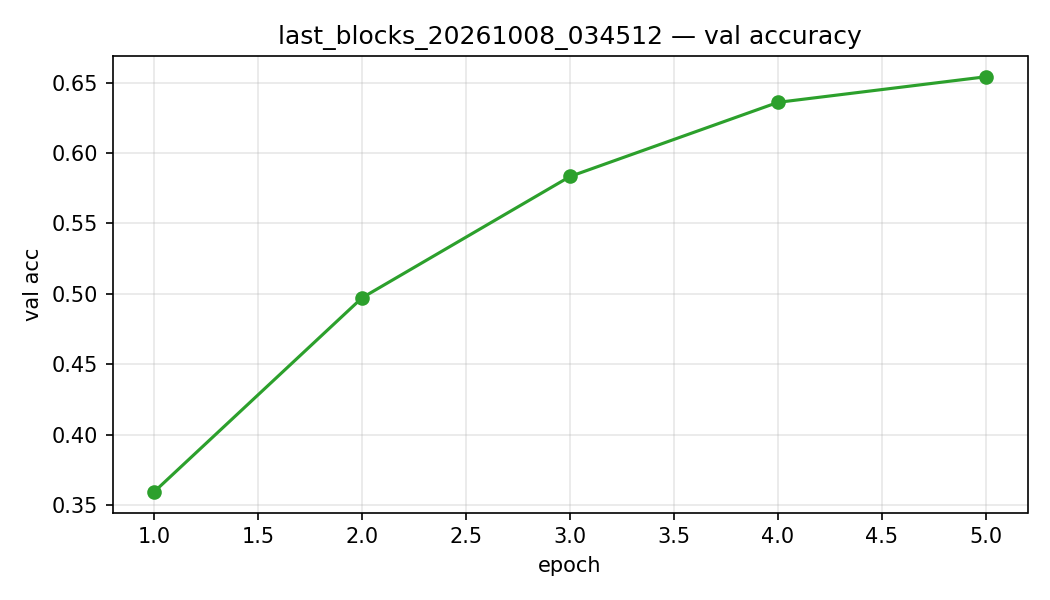

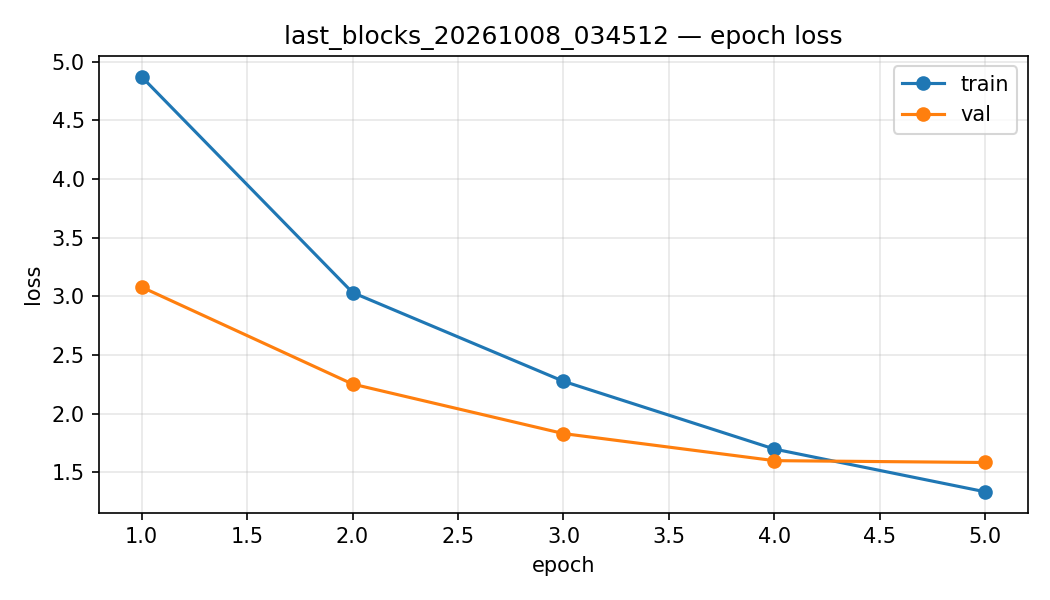

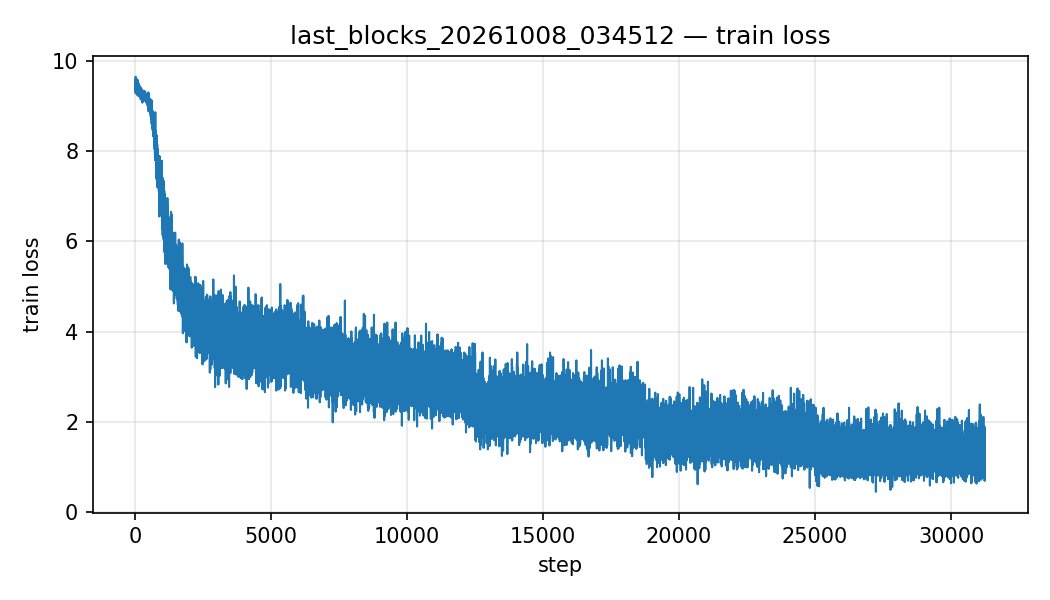

In [9]:
from IPython.display import Image, display
subprocess.run(["python", "scripts/plot_curves.py", "--run_dir", str(RUN_DIR),
                "--out_dir", str(RUN_DIR / "figures")], check=True)
for plot in sorted((RUN_DIR / "figures").glob("*.png")):
    display(Image(filename=str(plot)))


## After choosing

Summarize validation results and the selection rationale in progress_log.md. Keep raw logs and checkpoints on Drive. Retrain the chosen configuration from the pretrained model on all 450,000 training images, then evaluate official CodaBench predictions using a separate final-run launcher. This notebook deliberately stays on the holdout split and performs no official submissions.
